## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [33]:
Category = pd.read_csv('/Users/Shyam/Desktop/Ironhack-Bootcamp/Week 2/D4/lab-eda-univariate/amz_uk_price_prediction_dataset.csv')

In [37]:
# Frequency table
category_counts = Category['category'].value_counts()

# Display the frequency table
print(category_counts)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [77]:
type(category_counts)

pandas.core.series.Series

In [79]:
category_counts = pd.DataFrame(category_counts)
category_counts

,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978
...,...
Motorbike Chassis,107
Alexa Built-In Devices,107
Plugs,107


In [80]:
category_counts.head()

,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [60]:
Category.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

/var/folders/0w/j8jyj1vs7fd1hh9rpnk57syw0000gn/T/ipykernel_27111/1087708018.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


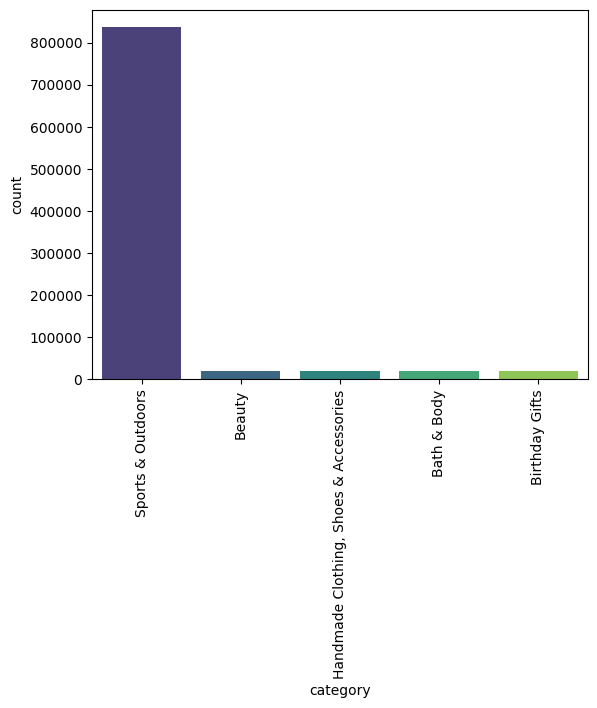

In [101]:
# First 5 categories

sns.barplot(
    x="category",
    y='count',
    data=category_counts.head(),
    palette='viridis'
)

plt.xticks(rotation=90)
plt.show()



<Figure size 1000x600 with 0 Axes>

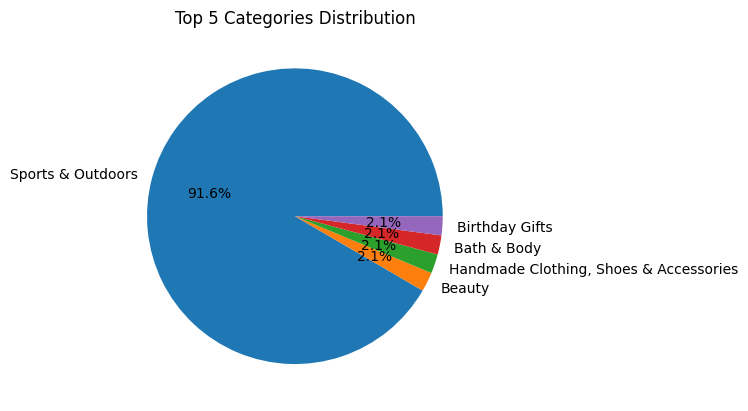

In [104]:
top5 = category_counts.head()

plt.figure(figsize=(10, 6))
top5.plot.pie(y='count', autopct='%1.1f%%', legend=False)
plt.title('Top 5 Categories Distribution')
plt.ylabel('')  # Hide y-label for better aesthetics
plt.show()  

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [67]:
mean_price = Category['price'].mean()
median_price = Category['price'].median()
mode_price = Category['price'].mode()[0]       # Get the first mode value
print(f"Mean Price: {mean_price}")
print(f"Median Price: {median_price}")
print(f"Mode Price: {mode_price}")

# Answer the business question
print(f"\nThe average price point of products listed is £{mean_price:.2f}.")
print(f"The most common price point (mode) is £{mode_price:.2f}.")

difference = mean_price - mode_price
if difference > 0:
    print(f"The average is £{difference:.2f} higher than the mode,")
    print("suggesting some expensive products are pulling the average upward.")
elif difference < 0:
    print(f"The average is £{abs(difference):.2f} lower than the mode.")
else:
    print("The average and mode are the same.")

Mean Price: 89.24380943923661
Median Price: 19.09
Mode Price: 9.99

The average price point of products listed is £89.24.
The most common price point (mode) is £9.99.
The average is £79.25 higher than the mode,
suggesting some expensive products are pulling the average upward.


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [ ]:
variance = Category['price'].var()
std_dev = Category['price'].std()
range_price = Category['price'].max() - Category['price'].min() # Range = max - min
interquartile_range = Category['price'].quantile(0.75) - Category['price'].quantile(0.25)   # IQR=Q3-Q1, Q3=75th percentile, Q1=25th percentile, Q2=median

print(f"\nVariance in Price: {variance}")
print(f"Standard Deviation in Price: {std_dev}")
print(f"Range in Price: {range_price}")
print(f"Interquartile Range in Price: {interquartile_range}")

# Interpretation
mean_price = Category['price'].mean()
print(f"\n=== Interpretation ===")
print(f"Average price: £{mean_price:.2f}")
print(f"Typical deviation from average: £{std_dev:.2f}")
print(f"Middle 50% of products vary by: £{interquartile_range:.2f}")
print(f"Full price range spans: £{range_price:.2f}")
print(f"\nConclusion: {'HIGH' if std_dev/mean_price > 0.5 else 'MODERATE'} price variability detected.")



Variance in Price: 119445.48532254901
Standard Deviation in Price: 345.60886175349873
Range in Price: 100000.0
Interquartile Range in Price: 36.0

=== Interpretation ===
Average price: £89.24
Typical deviation from average: £345.61
Middle 50% of products vary by: £36.00
Full price range spans: £100000.00

Conclusion: HIGH price variability detected.


3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

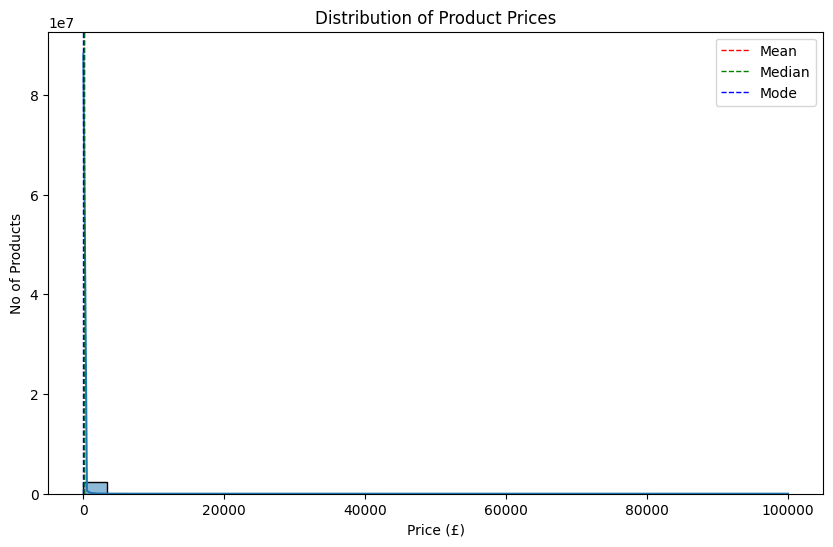

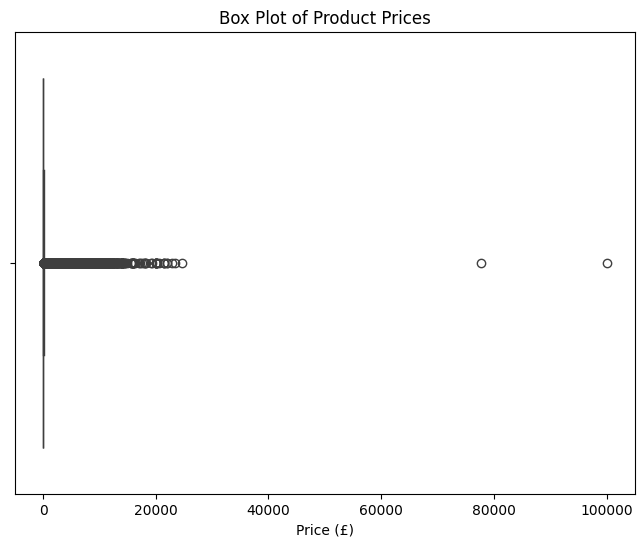

In [92]:

#histogram
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(Category['price'], bins=30, kde=True)
plt.title('Distribution of Product Prices')
plt.xlabel('Price (£)')
plt.ylabel('No of Products')
plt.axvline(mean_price, color='r', linestyle='dashed', linewidth=1, label='Mean')
plt.axvline(median_price, color='g', linestyle='dashed', linewidth=1, label='Median')
plt.axvline(mode_price, color='b', linestyle='dashed', linewidth=1, label='Mode')
plt.legend()
plt.show()

#box plot
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(x=Category['price'])
plt.title('Box Plot of Product Prices')
plt.xlabel('Price (£)')
plt.show()




### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [105]:
Category.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [109]:
# Calculate measures of centrality for ratings
mean_rating = Category['stars'].mean()
median_rating = Category['stars'].median()
mode_rating = Category['stars'].mode()[0]

print("=== Product Rating Analysis ===")
print(f"Mean stars:   {mean_rating:.2f}")
print(f"Median stars: {median_rating:.2f}")
print(f"Mode stars:   {mode_rating:.2f}")

#How customers generally rate products
if mean_rating > 4.0:
    print("Overall, products are rated highly by customers.")
elif mean_rating > 3.0:
    print("Products receive moderate ratings from customers.")
else:
    print("If its bad then products tend to receive lower ratings from customers.")

# Is there common trend in ratings?
if mean_rating == median_rating == mode_rating:
    print("Ratings are symmetrically distributed around the mean.")
elif mean_rating > median_rating > mode_rating:
    print("Ratings are right-skewed, with some lower ratings pulling the mean down.")
elif mean_rating < median_rating < mode_rating:
    print("Ratings are left-skewed, with some higher ratings pulling the mean up.")
else:
    print("Ratings distribution is complex, with no clear skewness.")
    


=== Product Rating Analysis ===
Mean stars:   2.15
Median stars: 0.00
Mode stars:   0.00
If its bad then products tend to receive lower ratings from customers.
Ratings distribution is complex, with no clear skewness.


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [112]:
# Calculate measures of dispersion for ratings
variance_rating = Category['stars'].var()
std_dev_rating = Category['stars'].std()
range_rating = Category['stars'].max() - Category['stars'].min()
interquartile_range_rating = Category['stars'].quantile(0.75) - Category['stars'].quantile(0.25)

print(f"\nVariance in Ratings: {variance_rating}")
print(f"Standard Deviation in Ratings: {std_dev_rating}")
print(f"Range in Ratings: {range_rating}")
print(f"Interquartile Range in Ratings: {interquartile_range_rating}")
print(f"\nThe average rating is {mean_rating:.2f} stars with a standard deviation of {std_dev_rating:.2f}.")

# Are ratings consistent or varied?
if std_dev_rating < 0.5:
    print("Customer ratings are fairly consistent.")
elif std_dev_rating < 1.0:
    print("Customer ratings show moderate variability.")
else:
    print("Customer ratings are quite varied.")




Variance in Ratings: 4.817434029796864
Standard Deviation in Ratings: 2.194865378513421
Range in Ratings: 5.0
Interquartile Range in Ratings: 4.4

The average rating is 2.15 stars with a standard deviation of 2.19.
Customer ratings are quite varied.


3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [114]:
# Calculate the skewness and kurtosis for ratings
skewness_rating = Category['stars'].skew()
kurtosis_rating = Category['stars'].kurtosis()

print(f"\nSkewness of Ratings: {skewness_rating}")
print(f"Kurtosis of Ratings: {kurtosis_rating}")

# Are ratings normally distributed or lean towards higher or lower values?
if skewness_rating > 0.5:
    print("Ratings are right-skewed, indicating a tendency towards lower ratings.")
elif skewness_rating < -0.5:
    print("Ratings are left-skewed, indicating a tendency towards higher ratings.")
else:
    print("Ratings are fairly symmetrically distributed.")


Skewness of Ratings: 0.08120735761080881
Kurtosis of Ratings: -1.9260061280432994
Ratings are fairly symmetrically distributed.


4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


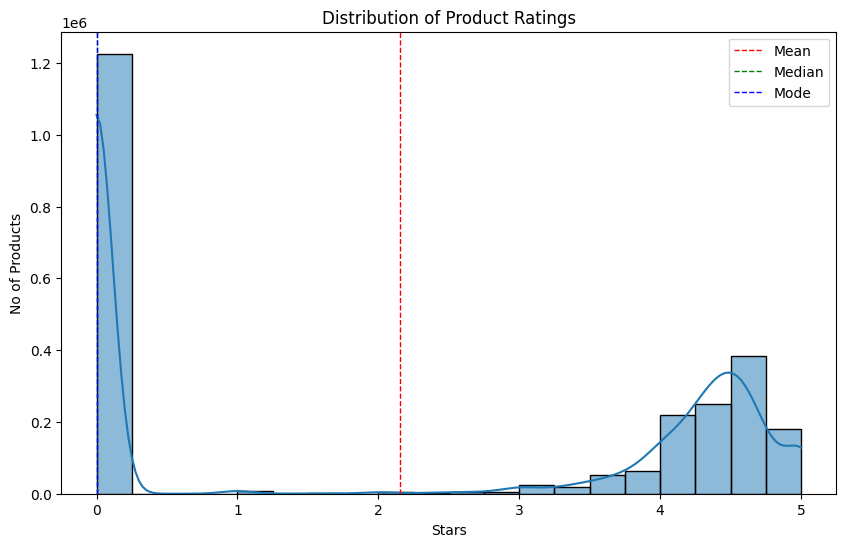

In [ ]:
# Plot histogram and box plot for ratings
fig, ax = plt.subplots(figsize=(10, 6))              # 10x6 inches   
sns.histplot(Category['stars'], bins=20, kde=True).  #kde=True adds a kernel density estimate line
plt.title('Distribution of Product Ratings')
plt.xlabel('Stars')
plt.ylabel('No of Products')
plt.axvline(mean_rating, color='r', linestyle='dashed', linewidth=1, label='Mean')      
plt.axvline(median_rating, color='g', linestyle='dashed', linewidth=1, label='Median')
plt.axvline(mode_rating, color='b', linestyle='dashed', linewidth=1, label='Mode')
plt.legend()
plt.show()

#

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 